In [1]:
import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu, zscore

from sklearn.base import BaseEstimator
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index, median_survival_times
from sksurv.metrics import concordance_index_censored, cumulative_dynamic_auc

In [2]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sns.set_style("whitegrid")
np.random.seed(42)

kmf = KaplanMeierFitter()

# Data Cleaning and Pre-processing

In [3]:
clinical_693 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\mRNAseq_693\Clinical\CGGA.mRNAseq_693_clinical.20200506.txt\CGGA.mRNAseq_693_clinical.20200506.txt",
    sep="\t",
    low_memory=False
)

expression_693 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\mRNAseq_693\Gene Expression\CGGA.mRNAseq_693.RSEM-genes.20200506.txt\CGGA.mRNAseq_693.RSEM-genes.20200506.txt",
    sep="\t",
    low_memory=False
)

mutation_286 = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\WEseq_286\Somatic Mutation\CGGA.WEseq_286.20200506.txt\CGGA.WEseq_286.20200506.txt",
    sep="\t",
    low_memory=False
)

In [4]:
expr_ids = set(expression_693.columns[1:])     
mut_ids = set(mutation_286.columns[1:])         

overlap = expr_ids & mut_ids

print("Expression patients:", len(expr_ids))
print("Mutation patients:", len(mut_ids))
print("Overlap:", len(overlap))

Expression patients: 693
Mutation patients: 286
Overlap: 185


## Clinical

In [5]:
# clinical_693.head(2)

In [6]:
clinical_693["Grade"].value_counts().sort_index()

Grade
WHO II     188
WHO III    255
WHO IV     249
Name: count, dtype: int64

In [7]:
PRIMARY_ONLY = True  # True: primary tumours only; False: primary and recurrent

clinical_693 = clinical_693[
    clinical_693["Grade"].str.strip() == "WHO IV"
].copy()

if PRIMARY_ONLY:
    clinical_693 = clinical_693[clinical_693["PRS_type"].str.strip() == "Primary"].copy()

print(f"Grade IV tumours kept: {len(clinical_693)} ({'primary only' if PRIMARY_ONLY else 'primary and recurrent'})")

Grade IV tumours kept: 140 (primary only)


In [8]:
clinical_693.shape

(140, 13)

### Feature Set

In [9]:
clinical_final = clinical_693[
    [
        "CGGA_ID",
        "Censor (alive=0; dead=1)",
        "OS",
        "Gender",
        "Age"
    ]
].copy()

clinical_final = clinical_final.rename(columns={
    "CGGA_ID": "patient_id",
    "Censor (alive=0; dead=1)": "event",
    "OS": "time",
    "Gender": "gender",
    "Age": "age"
})

In [10]:
clinical_final["gender"] = (
    clinical_final["gender"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "female": 1,
        "male": 0
    })
)
assert clinical_final["gender"].notnull().all()

clinical_final["event"] = pd.to_numeric(clinical_final["event"], errors="coerce")

In [11]:
clinical_final["time"] = pd.to_numeric(clinical_final["time"], errors="coerce")
clinical_final["age"] = pd.to_numeric(clinical_final["age"], errors="coerce")

clinical_final = clinical_final.dropna(
    subset=["event", "time", "age"]
).set_index("patient_id")

assert clinical_final["time"].notnull().all()
assert clinical_final["event"].isin([0, 1]).all()

clinical_final = clinical_final[~clinical_final.index.duplicated(keep="first")]

clinical_final = clinical_final[["event", "time", "gender", "age"]]

In [12]:
clinical_final = clinical_final.astype({
    "event": int,
    "time": float,
    "gender": int,
    "age": float,
})

# clinical_final.head()

In [13]:
n_before = len(clinical_final)
clinical_final = clinical_final[~(clinical_final["age"] < 18)]
print(f"Patients under 18 excluded: {n_before - len(clinical_final)}")

Patients under 18 excluded: 1


## Somatic Mutation

In [14]:
mutation_286 = mutation_286.rename(columns={"Unnamed: 0": "Gene"})

### Feature Set

In [15]:
selected_mutations_df = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\somatic_mutation_features.tsv",
    sep="\t"
)

In [16]:
mutation_genes = selected_mutations_df["Gene"].tolist()

In [17]:
mutation_final = mutation_286[
    mutation_286["Gene"].isin(mutation_genes)
].copy()

mutation_final = mutation_final.set_index("Gene").T

mutation_duplicates = mutation_final.index[mutation_final.index.duplicated()].unique()
print(f"Duplicates: {len(mutation_duplicates)}")
mutation_final = mutation_final[~mutation_final.index.duplicated(keep="first")]

mutation_final = mutation_final.reindex(columns=mutation_genes, fill_value=np.nan)
mutation_final = mutation_final.rename_axis(None, axis=1)
mutation_final = mutation_final.add_suffix("_mut")
mutation_final = mutation_final.notna().astype(int)
mutation_final.index.name = "patient_id"

# mutation_final.head(5)

Duplicates: 0


## Gene Expression

In [18]:
expression_693 = expression_693.rename(columns={"Gene_Name": "Gene"})

In [19]:
expression_fpkm = expression_693.set_index("Gene").apply(pd.to_numeric, errors="coerce")
expression_tpm = expression_fpkm.div(expression_fpkm.sum(axis=0), axis=1) * 1e6
expression_693 = expression_tpm.reset_index()

### Feature Set

In [20]:
selected_expression_df = pd.read_csv(
    r"C:\Users\abbyn\OneDrive\Desktop\Research Project\Biological Feature Selection\Final Feature Sets\gene_expr_features.tsv",
    sep="\t"
)

In [21]:
expression_genes = selected_expression_df["Gene"].tolist()

In [22]:
expression_genes = [gene for gene in expression_genes if gene != "HN1"]

In [23]:
available_genes = [gene for gene in expression_genes if gene in expression_693["Gene"].values]
expression_original = expression_693[expression_693["Gene"].isin(available_genes)].copy()

missing_genes = [gene for gene in expression_genes if gene not in expression_693["Gene"].values]

print("Missing genes:")
print(missing_genes)

expression_original = expression_original.set_index("Gene")
expression_original = expression_original.T
expression_original = expression_original.apply(pd.to_numeric, errors="coerce")

expression_duplicates = expression_original.index[expression_original.index.duplicated()].unique()
print(f"Duplicates: {len(expression_duplicates)}")
expression_original = expression_original.groupby(expression_original.index).median()

expression_original = expression_original.add_suffix("_exp")
expression_original = expression_original.rename_axis(None, axis=1)

expression_final = np.log1p(expression_original)

expression_final.index.name = "patient_id"
expression_final = expression_final[[f"{gene}_exp" for gene in available_genes]]

expr_cols = expression_final.columns

# expression_final.head()

Missing genes:
['EZHIP']
Duplicates: 0


## Final Feature Set

In [24]:
merged_df = pd.concat([clinical_final, mutation_final, expression_final], axis=1, join='inner')

In [25]:
print("Clinical:", clinical_final.shape)
print("Mutation:", mutation_final.shape)
print("Expression:", expression_final.shape)
print("Merged:", merged_df.shape)

Clinical: (132, 4)
Mutation: (286, 10)
Expression: (693, 68)
Merged: (35, 82)


In [26]:
print(f"Patients in clinical: {len(clinical_final)}")
print(f"Patients after adding mutation: {len(clinical_final.index.intersection(mutation_final.index))}")
print(f"Final merged: {len(merged_df)}")

Patients in clinical: 132
Patients after adding mutation: 35
Final merged: 35


In [27]:
# merged_df.head()

In [28]:
Path(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_gbm").mkdir(parents=True, exist_ok=True)
merged_df.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_gbm\merged_df.csv", index=False)

validation_df = pd.concat([clinical_final, expression_final], axis=1, join='inner')
validation_df = validation_df.join(mutation_final, how='left')
validation_df.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\CGGA\saved_models\cgga_gbm\validation_df.csv", index=False)

# Exploratory Data Analysis

## Survival Outcomes

event
1    80.0
0    20.0
Name: count, dtype: float64


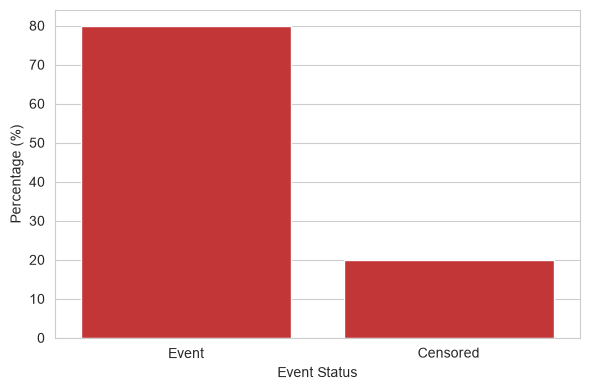

In [29]:
event_counts = merged_df["event"].value_counts().reindex([1, 0])
event_percentages = (event_counts / event_counts.sum() * 100).round(4)
print(event_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=event_counts.index.map({0: "Censored", 1: "Event"}),
    y=event_percentages.values,
    ax=ax,
    color="#D91F22"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count      35.000000
mean      696.942857
std       615.857649
min        44.000000
25%       260.500000
50%       378.000000
75%       991.000000
max      2557.000000
Name: time, dtype: float64


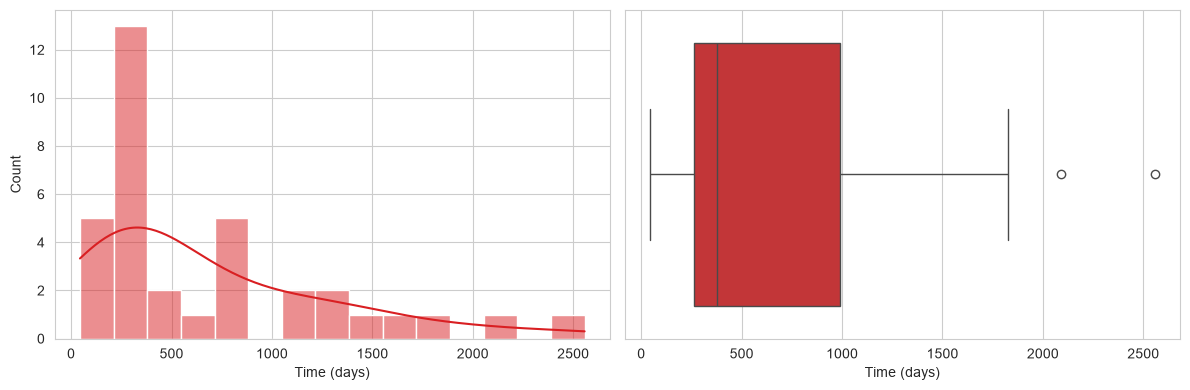

In [30]:
time_described = merged_df["time"].describe()
print(time_described)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["time"], bins=15, kde=True, ax=ax1, color="#D91F22")
ax1.set_xlabel("Time (days)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["time"], ax=ax2, color="#D91F22")
ax2.set_xlabel("Time (days)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

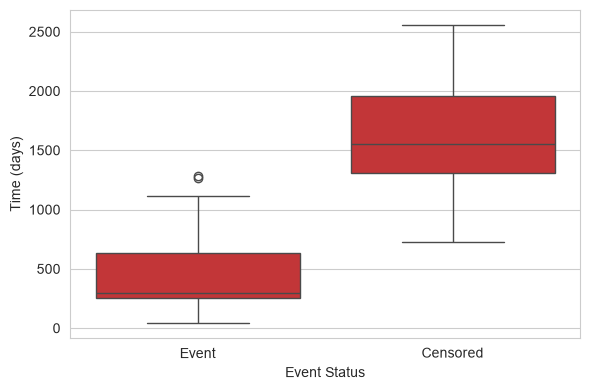

In [31]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(
    x=merged_df["event"].map({0: "Censored", 1: "Event"}),
    y=merged_df["time"],
    order=["Event", "Censored"],
    ax=ax,
    color="#D91F22"
)
ax.set_xlabel("Event Status")
ax.set_ylabel("Time (days)")
plt.tight_layout()
plt.show()

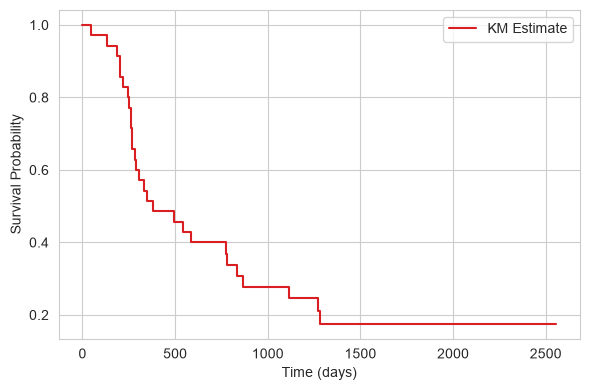

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))

kmf.fit(merged_df["time"], merged_df["event"], label="KM Estimate")
kmf.plot_survival_function(ax=ax, color="#D91F22", ci_show=False)

ax.set_xlabel("Time (days)")
ax.set_ylabel("Survival Probability")
ax.get_legend().set_title(None)
plt.tight_layout()
plt.show()

## Clinical

gender
1    45.7143
0    54.2857
Name: count, dtype: float64


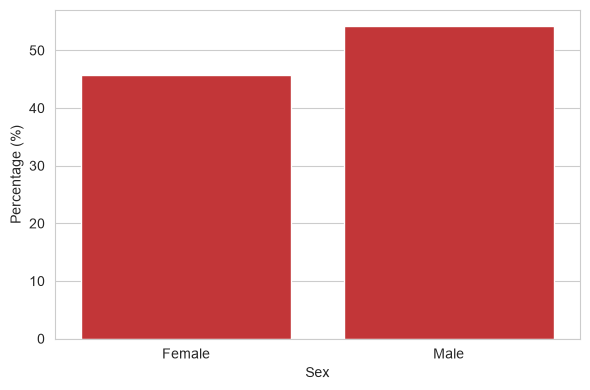

In [33]:
gender_counts = merged_df["gender"].value_counts().reindex([1, 0])
gender_percentages = (gender_counts / gender_counts.sum() * 100).round(4)
print(gender_percentages)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=gender_counts.index.map({0: "Male", 1: "Female"}),
    y=gender_percentages.values,
    ax=ax,
    color="#D91F22"
)
ax.set_xlabel("Sex")
ax.set_ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

count    35.000000
mean     53.314286
std      14.748423
min      19.000000
25%      46.000000
50%      57.000000
75%      65.000000
max      76.000000
Name: age, dtype: float64


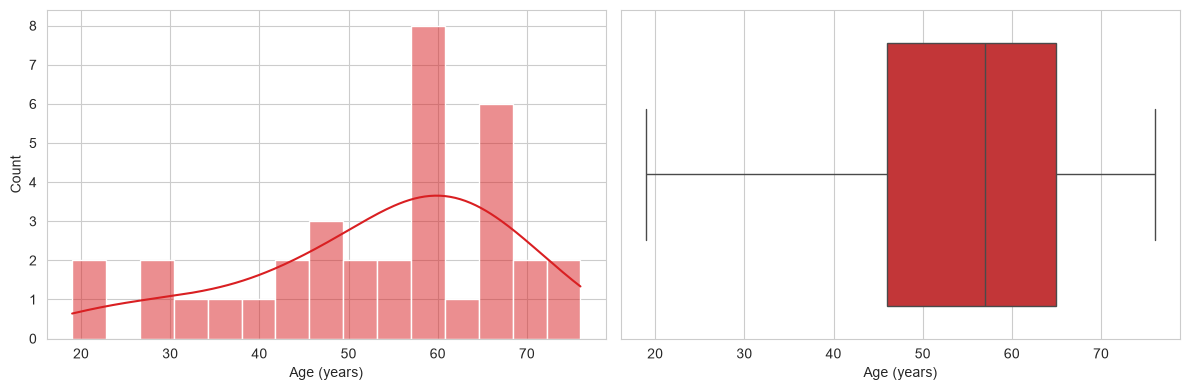

In [34]:
age_described = merged_df["age"].describe()
print(age_described)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_df["age"], bins=15, kde=True, ax=ax1, color="#D91F22")
ax1.set_xlabel("Age (years)")
ax1.set_ylabel("Count")

sns.boxplot(x=merged_df["age"], ax=ax2, color="#D91F22")
ax2.set_xlabel("Age (years)")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

## Somatic Mutation

In [35]:
merged_mutation_df = merged_df[mutation_final.columns]
sparsity = ((merged_mutation_df == 0).sum().sum() / merged_mutation_df.size)
print("Sparsity:", sparsity)

Sparsity: 0.88


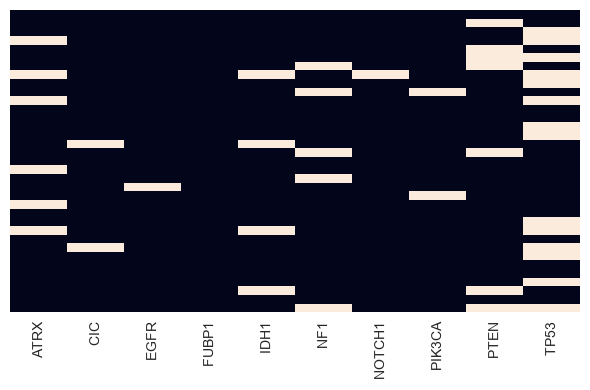

In [36]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(merged_mutation_df.rename(columns=lambda c: c.replace('_mut', '').upper()),
            cbar=False, yticklabels=False, ax=ax)
ax.set_ylabel(None)
plt.tight_layout()
plt.show()

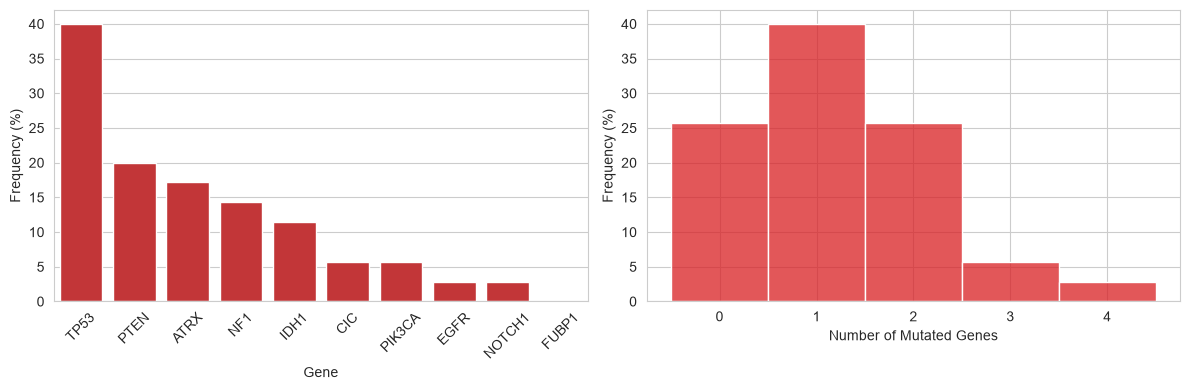

In [37]:
mutation_freq = (merged_mutation_df.mean().sort_values(ascending=False) * 100)
mutation_freq.index = mutation_freq.index.str.replace('_mut', '').str.upper()
mutation_burden = merged_mutation_df.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=mutation_freq.index, y=mutation_freq.values, color="#D91F22", ax=axes[0])
axes[0].set_xlabel("Gene")
axes[0].set_ylabel("Frequency (%)")
axes[0].tick_params(axis='x', rotation=45)

sns.histplot(mutation_burden, discrete=True, color="#D91F22", stat="percent", ax=axes[1])
axes[1].set_xlabel("Number of Mutated Genes")
axes[1].set_ylabel("Frequency (%)")
axes[1].set_xticks(range(int(mutation_burden.max()) + 1))

plt.tight_layout()
plt.show()

## Gene Expression

In [38]:
merged_expression_df = merged_df[expression_final.columns]

### Original

In [39]:
original_expression_df = merged_df[expression_original.columns]

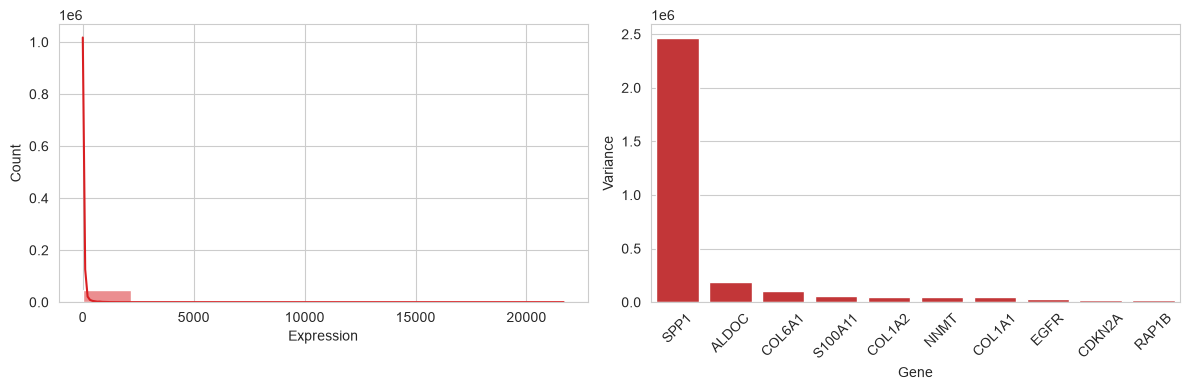

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(expression_original.values.flatten(), bins=10, kde=True, color="#D91F22", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = expression_original.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#D91F22", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Log-transformed

In [41]:
merged_expression_df = merged_df[expression_final.columns]

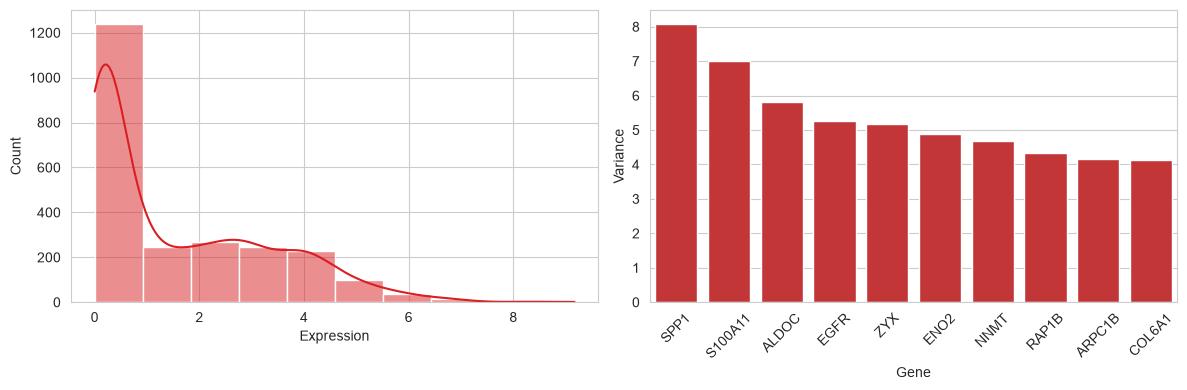

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(merged_expression_df.values.flatten(), bins=10, kde=True, color="#D91F22", ax=axes[0])
axes[0].set_xlabel("Expression")
axes[0].set_ylabel("Count")

top10_var = merged_expression_df.var().sort_values(ascending=False).head(10)
top10_var.index = top10_var.index.str.replace('_exp', '')
sns.barplot(x=top10_var.index, y=top10_var.values, color="#D91F22", ax=axes[1])
axes[1].set_ylabel("Variance")
axes[1].set_xlabel("Gene")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Dimensionality Reduction

In [43]:
dimred_merged_df = merged_df.copy()

## Somatic Mutation

In [44]:
tcga_dir = r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm"

tcga_dimred_cols = pd.read_csv(os.path.join(tcga_dir, "dimred_merged_df.csv"), nrows=0).columns
gbm_trio_mutations = [c for c in tcga_dimred_cols if c.endswith("_mut")]
print(f"Mutations kept (from TCGA): {gbm_trio_mutations}")

not_gbm_trio = [col for col in merged_mutation_df.columns if col not in gbm_trio_mutations]
not_gbm_trio_present = [c for c in not_gbm_trio if c in dimred_merged_df.columns]
dimred_merged_df.drop(columns=not_gbm_trio_present, inplace=True)

Mutations kept (from TCGA): ['EGFR_mut', 'PTEN_mut', 'TP53_mut']


## Gene Expression

In [45]:
_, tcga_coef_df, _ = joblib.load(os.path.join(tcga_dir, "global_enet_result.pkl"))
tcga_gene_weights = tcga_coef_df.set_index("feature")["coef"]
tcga_score_scaler = joblib.load(os.path.join(tcga_dir, "tcga_score_scaler.pkl"))
score_cols = list(tcga_score_scaler.feature_names_in_)
print(f"Pathway scores kept (from TCGA): {score_cols}")

Pathway scores kept (from TCGA): ['farg_score_exp', 'classical_score_exp', 'hypoxia_score_exp', 'emt_score_exp', 'mesenchymal_score_exp', 'g2m_score_exp', 'pi3k_akt_mtor_score_exp', 'proneural_score_exp']


In [46]:
g2m_genes         = ["AURKB_exp", "RPA2_exp", "MCM5_exp", "CDC45_exp", "MCM6_exp"]
pi3k_mtor_genes   = ['MAPK1_exp', 'MAPK8_exp', 'MAP3K7_exp', 'MAP2K6_exp', 'MAPK9_exp']
hypoxia_genes     = ['ALDOC_exp', 'ALDOB_exp', 'ENO2_exp', 'ENO3_exp', 'PFKP_exp']
emt_genes         = ['COL1A2_exp', 'COL1A1_exp', 'COL5A1_exp', 'COL3A1_exp', 'COL4A2_exp']
mesenchymal_genes = ['ARPC1B_exp', 'S100A11_exp', 'CTSC_exp', 'GLIPR1_exp', 'NNMT_exp']
proneural_genes   = ['RAB33A_exp', 'HDAC2_exp', 'MYT1_exp', 'MTSS1_exp']
classical_genes   = ['PTPRA_exp', 'ELOVL2_exp', 'MLC1_exp', 'SOX9_exp', 'ARNTL_exp']
farg_genes        = ['RAP1B_exp', 'VAV3_exp', 'ZYX_exp', 'COL5A2_exp', 'SPP1_exp',
                     'COL6A1_exp', 'ITGA5_exp', 'SHC1_exp']

In [47]:
pathway_gene_map = {
    "G2M Pathway":          g2m_genes,
    "PI3K mTOR Pathway":    pi3k_mtor_genes,
    "Hypoxia Pathway":      hypoxia_genes,
    "EMT Pathway":          emt_genes,
    "Mesenchymal Pathway":  mesenchymal_genes,
    "Proneural Pathway":    proneural_genes,
    "Classical Pathway":    classical_genes,
    "FARG Pathway":         farg_genes,
}

pathway_features = {
    'farg_score_exp':          'FARG Pathway',
    'classical_score_exp':     'Classical Pathway',
    'hypoxia_score_exp':       'Hypoxia Pathway',
    'emt_score_exp':           'EMT Pathway',
    'mesenchymal_score_exp':   'Mesenchymal Pathway',
    'g2m_score_exp':           'G2M Pathway',
    'pi3k_akt_mtor_score_exp': 'PI3K mTOR Pathway',
    'proneural_score_exp':     'Proneural Pathway',
}

In [48]:
def score_pathway(df, genes, weights):
    needed = [g for g in genes if weights.get(g, 0) != 0]
    missing = [g for g in needed if g not in df.columns]
    if missing:
        raise KeyError(f"Genes with non-zero TCGA weight missing from CGGA: {missing}")
    if not needed:
        return pd.Series(0.0, index=df.index)
    return df[needed].apply(zscore).multiply(weights.loc[needed].values, axis=1).sum(axis=1)

for score_col in score_cols:
    genes = pathway_gene_map[pathway_features[score_col]]
    dimred_merged_df[score_col] = score_pathway(dimred_merged_df, genes, tcga_gene_weights)

In [49]:
expr_cols = [c for c in dimred_merged_df.columns if c.endswith("_exp") and c not in score_cols]
dimred_merged_df.drop(columns=expr_cols, inplace=True)
dimred_merged_df[score_cols] = tcga_score_scaler.transform(dimred_merged_df[score_cols])
# dimred_merged_df.head(5)

# Prognostic Model

In [50]:
PROGNOSTIC_FULL_COHORT = True  # True: all patients with expression data; False: only those with mutation data

if PROGNOSTIC_FULL_COHORT:
    prog_df = pd.concat([clinical_final, expression_final], axis=1, join='inner')
    prog_df = prog_df.join(mutation_final[gbm_trio_mutations], how='left')

    for score_col in score_cols:
        genes = pathway_gene_map[pathway_features[score_col]]
        prog_df[score_col] = score_pathway(prog_df, genes, tcga_gene_weights)
    prog_df[score_cols] = tcga_score_scaler.transform(prog_df[score_cols])
    prog_expression_df = prog_df[expression_final.columns]
else:
    prog_df = dimred_merged_df.copy()
    prog_expression_df = merged_expression_df

n_mut = int(prog_df[gbm_trio_mutations].notna().all(axis=1).sum())
print(f"Prognostic validation cohort: {len(prog_df)} patients, {int(prog_df['event'].sum())} events "
      f"({n_mut} with mutation data)")

Prognostic validation cohort: 132 patients, 110 events (35 with mutation data)


In [51]:
cohort_clin = clinical_693.set_index("CGGA_ID").reindex(prog_df.index)
n = len(prog_df)
print(f"Patients: {n}")
print(f"Deaths: {int(prog_df['event'].sum())} ({prog_df['event'].mean():.1%})")
print(f"Age: mean {prog_df['age'].mean():.1f} (SD {prog_df['age'].std():.1f}), median {prog_df['age'].median():.1f} years")
print(f"Female: {int(prog_df['gender'].sum())} ({prog_df['gender'].mean():.1%})")

kmf_os = KaplanMeierFitter().fit(prog_df["time"], prog_df["event"])
os_ci = median_survival_times(kmf_os.confidence_interval_)
fmt = lambda v: "NR" if np.isinf(v) else f"{v:.0f}"
print(f"Median OS: {fmt(kmf_os.median_survival_time_)} days "
      f"(95% CI {fmt(os_ci.iloc[0, 0])}-{fmt(os_ci.iloc[0, 1])})")
kmf_fu = KaplanMeierFitter().fit(prog_df["time"], 1 - prog_df["event"])
print(f"Median follow-up (reverse KM): {kmf_fu.median_survival_time_:.0f} days")
for label, s in zip(["1-year", "3-year", "5-year"], kmf_os.survival_function_at_times([365, 1095, 1825]).values):
    print(f"{label} survival: {s:.1%}")

idh = cohort_clin["IDH_mutation_status"].str.strip()
idh_known = idh.dropna()
print(f"IDH-mutant: {int((idh_known == 'Mutant').sum())}/{len(idh_known)} with known status "
      f"({(idh_known == 'Mutant').mean():.1%}); unknown: {int(idh.isna().sum())}")

Patients: 132
Deaths: 110 (83.3%)
Age: mean 52.6 (SD 12.8), median 55.0 years
Female: 53 (40.2%)
Median OS: 494 days (95% CI 398-623)
Median follow-up (reverse KM): 2068 days
1-year survival: 63.3%
3-year survival: 19.5%
5-year survival: 15.4%
IDH-mutant: 21/125 with known status (16.8%); unknown: 7


## Feature Selection

In [52]:
with open(os.path.join(tcga_dir, "cph_multi.pkl"), "rb") as f:
    tcga_cph_multi = pickle.load(f)

clinical_features = {'age': 'Age', 'gender': 'Sex'}
mutation_features = {m: m.replace('_mut', '') for m in gbm_trio_mutations}
all_features = {**clinical_features, **mutation_features,
                **{c: pathway_features[c] for c in score_cols}}

tcga_summary = tcga_cph_multi.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
sig = tcga_summary[tcga_summary['p'] < 0.05]
sig_pathways = [f for f in sig.index if f in score_cols]
final_features = ["age"] + sig_pathways

print("Significant in the TCGA multivariable Cox model (pre-specified for CGGA):")
print(sig.rename(index=all_features).round(3).to_string())

Significant in the TCGA multivariable Cox model (pre-specified for CGGA):
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.035                1.021                1.050  0.000
FARG Pathway           1.453                1.122                1.882  0.005
Hypoxia Pathway        0.802                0.678                0.948  0.010
Proneural Pathway      1.265                1.017                1.574  0.035


In [53]:
tcga_dimred_df = pd.read_csv(os.path.join(tcga_dir, "dimred_merged_df.csv"))

def fit_tcga_model(features):
    model = CoxPHFitter()
    model.fit(tcga_dimred_df[features + ["time", "event"]], duration_col="time", event_col="event")
    return model

tcga_cph = fit_tcga_model(final_features)
tcga_median_pi = tcga_cph.predict_partial_hazard(tcga_dimred_df[final_features]).median()

print(f"TCGA prognostic model ({', '.join(all_features.get(f, f) for f in final_features)}):")
print(tcga_cph.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]
      .rename(index=all_features).round(3).to_string())
print(f"\nTCGA median PI (risk-group cut-off): {tcga_median_pi:.4f}")

TCGA prognostic model (Age, FARG Pathway, Hypoxia Pathway, Proneural Pathway):
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.034                1.020                1.048  0.000
FARG Pathway           1.300                1.100                1.538  0.002
Hypoxia Pathway        0.821                0.703                0.959  0.013
Proneural Pathway      1.190                1.007                1.407  0.041

TCGA median PI (risk-group cut-off): 1.0611


In [54]:
df_multi = prog_df[["time", "event"] + final_features].copy()
cph_multi = CoxPHFitter()
cph_multi.fit(df_multi, duration_col="time", event_col="event")
cph_multi.print_summary()

cgga_summary = cph_multi.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
tcga_model_summary = tcga_cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]

for f in final_features:
    t, c = tcga_model_summary.loc[f], cgga_summary.loc[f]
    print(f"{all_features.get(f, f)}: "
          f"TCGA HR={t['exp(coef)']:.2f} ({t['exp(coef) lower 95%']:.2f}-{t['exp(coef) upper 95%']:.2f}), p={t['p']:.3f} | "
          f"CGGA HR={c['exp(coef)']:.2f} ({c['exp(coef) lower 95%']:.2f}-{c['exp(coef) upper 95%']:.2f}), p={c['p']:.3f}")

<lifelines.CoxPHFitter: fitted with 132 total observations, 22 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 132
number of events observed = 110
   partial log-likelihood = -453.10
         time fit was run = 2026-10-26 14:29:51 UTC

---
                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                            
age                  0.02      1.02      0.01            0.00            0.04                1.00                1.04
farg_score_exp       0.16      1.18      0.10           -0.03            0.35                0.97                1.42
hypoxia_score_exp   -0.32      0.73      0.15           -0.62           -0.01                0.54                0.99
proneural_score_exp  0.20      1.22      0.17           -0.13            0.52                0.88                1.69

                     cmp to     z    p  -log2(p)
covariate                                       
age                    0.00  2.47 0.01      6.20
farg_score_exp         0.00  1.69 0.09      3.46
hypoxia_score_exp      0.00 -2.04 0.04      4.59
proneural_score_exp    0.00  1.17 0.24      2.04
---
Concordance = 0.61
Partial AIC = 914.20
log-likelihood ratio test = 13.34 on 4 df
-log2(p) of ll-ratio test = 6.68

Age: TCGA HR=1.03 (1.02-1.05), p=0.000 | CGGA HR=1.02 (1.00-1.04), p=0.014
FARG Pathway: TCGA HR=1.30 (1.10-1.54), p=0.002 | CGGA HR=1.18 (0.97-1.42), p=0.091
Hypoxia Pathway: TCGA HR=0.82 (0.70-0.96), p=0.013 | CGGA HR=0.73 (0.54-0.99), p=0.042
Proneural Pathway: TCGA HR=1.19 (1.01-1.41), p=0.041 | CGGA HR=1.22 (0.88-1.69), p=0.243


In [55]:
report_labels = {
    "age": "Age (per year)",
    "pi3k_akt_mtor_score_exp": "PI3K/AKT/mTOR", "emt_score_exp": "EMT",
    "hypoxia_score_exp": "Hypoxia", "g2m_score_exp": "G2/M checkpoint",
    "farg_score_exp": "FARG", "classical_score_exp": "Classical",
    "mesenchymal_score_exp": "Mesenchymal", "proneural_score_exp": "Proneural",
}

In [56]:
def plot_forest(features, cohorts, title=None):
    """Forest plot with an HR (95% CI) and p table. cohorts = [(name, summary, colour, marker), ...],
    where summary is a lifelines summary indexed by feature. Bold values: p < 0.05."""
    from matplotlib.lines import Line2D
    from matplotlib.ticker import NullLocator
    ink, muted, grid = "#222222", "#6b6b6b", "#ececec"
    n_c = len(cohorts)
    offsets = [0.0] if n_c == 1 else list(np.linspace(-0.2, 0.2, n_c))
    labels = [report_labels.get(f, f) for f in features]

    fig, (ax, ax_t) = plt.subplots(
        1, 2, sharey=True, figsize=(9, max(2.8, len(features) * (0.3 * n_c + 0.12) + 1.0)),
        gridspec_kw={"width_ratios": [3, 2], "wspace": 0.03})

    lo = min(s.loc[features, "exp(coef) lower 95%"].min() for _, s, _, _ in cohorts)
    hi = max(s.loc[features, "exp(coef) upper 95%"].max() for _, s, _, _ in cohorts)
    x_lo, x_hi = min(lo * 0.9, 0.8), max(hi * 1.1, 1.25)

    for k, (name, s, colour, marker) in enumerate(cohorts):
        for i, f in enumerate(features):
            r, y = s.loc[f], i + offsets[k]
            weight = "bold" if r["p"] < 0.05 else "normal"
            ax.plot([r["exp(coef) lower 95%"], r["exp(coef) upper 95%"]], [y, y],
                    color=colour, lw=2, solid_capstyle="round", zorder=2)
            ax.scatter(r["exp(coef)"], y, s=60, marker=marker, zorder=3, linewidths=1.5,
                       edgecolors="white", facecolors=colour)
            if n_c > 1:
                ax_t.scatter(0.0, y, s=28, marker=marker, linewidths=1.4,
                             edgecolors="white", facecolors=colour)
            ci = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}\u2013{r['exp(coef) upper 95%']:.2f})"
            ax_t.text(0.06 if n_c > 1 else 0.0, y, ci, va="center", fontsize=10, color=ink, fontweight=weight)
            ax_t.text(0.8, y, "<0.001" if r["p"] < 0.001 else f"{r['p']:.3f}", va="center",
                      fontsize=10, color=ink, fontweight=weight)

    for a in (ax, ax_t):
        for i in range(len(features) - 1):
            a.axhline(i + 0.5, color=grid, lw=0.8, zorder=0)
    ax_t.text(0.06 if n_c > 1 else 0.0, -0.75, "HR (95% CI)", fontsize=10, color=muted, fontweight="bold", va="center")
    ax_t.text(0.8, -0.75, "p", fontsize=10, color=muted, fontweight="bold", va="center", fontstyle="italic")
    ax_t.set_xlim(-0.05, 1.05)
    ax_t.axis("off")

    ax.set_xscale("log")
    ticks = [t for t in [0.25, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 4] if x_lo <= t <= x_hi]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(x_lo, x_hi)
    for t in ticks:
        if t != 1:
            ax.axvline(t, color=grid, lw=0.8, zorder=0)
    ax.axvline(1, color="#9a9a9a", lw=1, ls="--", zorder=1)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#bdbdbd")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(labels, color=ink, fontsize=11)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=muted, labelsize=10)
    ax.set_ylim(len(features) - 0.5, -1.1)
    ax.set_xlabel("Hazard ratio (log scale)", color=muted, fontsize=10)

    if n_c > 1:
        handles = [Line2D([0], [0], marker=m, color=c, lw=2, markersize=7, markerfacecolor=c)
                   for _, _, c, m in cohorts]
        ax.legend(handles, [nm for nm, _, _, _ in cohorts], loc="upper left", ncol=n_c,
                  frameon=False, fontsize=10, bbox_to_anchor=(0, 1.02))
    plt.tight_layout()
    plt.show()

C:\Users\abbyn\AppData\Local\Temp\ipykernel_34492\1538720033.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


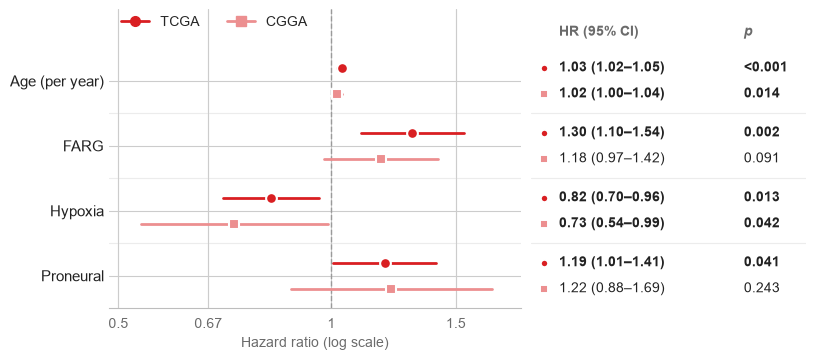

In [57]:
plot_forest(final_features,
            [("TCGA", tcga_model_summary, "#D91F22", "o"), ("CGGA", cgga_summary, "#EC8F90", "s")])

### Adjustment for Established Markers

In [58]:
clin = clinical_693.set_index("CGGA_ID")
restr_df = prog_df[["time", "event", "age"] + sig_pathways].copy()
restr_df["IDH1_mut"] = clin["IDH_mutation_status"].str.strip().reindex(restr_df.index).map({"Mutant": 1, "Wildtype": 0})
restr_df["MGMT_methylated"] = clin["MGMTp_methylation_status"].str.strip().reindex(restr_df.index).map({"methylated": 1, "un-methylated": 0})

known_idh = restr_df.dropna(subset=["IDH1_mut"])
idh_wt = known_idh[known_idh["IDH1_mut"] == 0]
idh_wt_mgmt = idh_wt.dropna(subset=["MGMT_methylated"])
print(f"Known IDH status: {len(known_idh)}/{len(restr_df)} (IDH-mutant excluded: {int(known_idh['IDH1_mut'].sum())})")
print(f"IDH-wildtype with known MGMT status: {len(idh_wt_mgmt)}/{len(idh_wt)}")

restr_labels = {**all_features, "MGMT_methylated": "MGMT methylated"}
base = ["age"] + sig_pathways
for label, d, cols in [
    ("All patients with known IDH",          known_idh,   base),
    ("IDH-wildtype only",                    idh_wt,      base),
    ("IDH-wildtype, known MGMT (unadjusted)", idh_wt_mgmt, base),
    ("IDH-wildtype, adjusted for MGMT",      idh_wt_mgmt, base + ["MGMT_methylated"]),
]:
    cph_restr = CoxPHFitter().fit(d[cols + ["time", "event"]], "time", "event")
    print()
    print(f"{label} (n={len(d)}, events={int(d['event'].sum())}): C-index = {cph_restr.concordance_index_:.3f}")
    print(cph_restr.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
          .rename(index=restr_labels).round(3).to_string())

Known IDH status: 125/132 (IDH-mutant excluded: 21)
IDH-wildtype with known MGMT status: 91/104

All patients with known IDH (n=125, events=106): C-index = 0.588
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.017                1.001                1.033  0.036
FARG Pathway           1.183                0.979                1.429  0.082
Hypoxia Pathway        0.781                0.570                1.070  0.124
Proneural Pathway      1.114                0.791                1.569  0.538

IDH-wildtype only (n=104, events=92): C-index = 0.569
                   exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                                    
Age                    1.017                1.000                1.035  0.051
FARG Pathway           1.024                0.825                1.273  0.827
Hyp

In [59]:
idh_known = restr_df.dropna(subset=["IDH1_mut"])
print(f"IDH-mutant: {int(idh_known['IDH1_mut'].sum())}, IDH-wildtype: {int((idh_known['IDH1_mut'] == 0).sum())}")

rows = []
for p in sig_pathways:
    wt = idh_known.loc[idh_known["IDH1_mut"] == 0, p]
    mut = idh_known.loc[idh_known["IDH1_mut"] == 1, p]
    _, p_val = mannwhitneyu(wt, mut, alternative="two-sided")
    rows.append({"Pathway": all_features.get(p, p),
                 "Median IDH-wildtype": round(wt.median(), 3),
                 "Median IDH-mutant": round(mut.median(), 3),
                 "Mann-Whitney p": round(p_val, 4)})
if rows:
    print(pd.DataFrame(rows).set_index("Pathway").to_string())
else:
    print("No significant pathways")

IDH-mutant: 21, IDH-wildtype: 104
                   Median IDH-wildtype  Median IDH-mutant  Mann-Whitney p
Pathway                                                                  
FARG Pathway                     0.340             -0.475          0.0008
Hypoxia Pathway                  0.126              0.571          0.0301
Proneural Pathway                0.149              0.404          0.2013


In [60]:
marker_cols = {"IDH_mutation_status": "IDH", "MGMTp_methylation_status": "MGMT"}
missing = clin.reindex(prog_df.index)[list(marker_cols)].isna().rename(columns=marker_cols)
print("Patients missing each marker:", missing.sum().to_dict())

miss_df = prog_df[["time", "event", "age"] + sig_pathways].copy()
miss_df["complete_markers"] = ~missing.any(axis=1)

rows = []
for complete, d in miss_df.groupby("complete_markers"):
    row = {"Group": "Complete markers" if complete else "Missing markers",
           "n": len(d), "Events": int(d["event"].sum()),
           "Median age": d["age"].median(), "Median follow-up (days)": d["time"].median()}
    for p in sig_pathways:
        f = CoxPHFitter().fit(d[["time", "event", "age", p]], "time", "event")
        r = f.summary.loc[p]
        row[f"{all_features.get(p, p)} HR (95% CI)"] = f"{r['exp(coef)']:.2f} ({r['exp(coef) lower 95%']:.2f}-{r['exp(coef) upper 95%']:.2f})"
        row[f"{all_features.get(p, p)} p"] = round(r["p"], 3)
    rows.append(row)
print(pd.DataFrame(rows).set_index("Group").T.to_string())

Patients missing each marker: {'IDH': 7, 'MGMT': 16}
Group                           Missing markers  Complete markers
n                                            22               110
Events                                       16                94
Median age                                 57.5              55.0
Median follow-up (days)                   653.0             432.0
FARG Pathway HR (95% CI)       1.06 (0.70-1.62)  1.13 (0.94-1.35)
FARG Pathway p                            0.778             0.195
Hypoxia Pathway HR (95% CI)    1.02 (0.66-1.58)  0.87 (0.71-1.08)
Hypoxia Pathway p                         0.917             0.212
Proneural Pathway HR (95% CI)  1.31 (0.75-2.28)  0.96 (0.76-1.21)
Proneural Pathway p                       0.343             0.741


## Performance Evaluation

### Discrimination

In [61]:
model_sets = {
    "Age only":       ["age"],
    "Pathways only":  sig_pathways,
    "Age + Pathways": final_features,
}
model_sets = {label: features for label, features in model_sets.items() if features}
tcga_models = {label: fit_tcga_model(features) for label, features in model_sets.items()}

In [62]:
def bootstrap_cindex(df, risk, n_boot=1000, seed=42):
    rng = np.random.default_rng(seed)
    time, event, risk = df["time"].values, df["event"].values, np.asarray(risk)
    point = concordance_index(time, -risk, event)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(df), len(df))
        boots.append(concordance_index(time[idx], -risk[idx], event[idx]))
    return point, np.percentile(boots, [2.5, 97.5])

In [63]:
cindex_results = {}
for label, features in model_sets.items():
    tcga_ci = concordance_index(tcga_dimred_df["time"],
                                -tcga_models[label].predict_partial_hazard(tcga_dimred_df[features]),
                                tcga_dimred_df["event"])
    risk = tcga_models[label].predict_partial_hazard(prog_df[features])
    point, (lo, hi) = bootstrap_cindex(prog_df, risk)
    cindex_results[label] = (point, lo, hi)
    print(f"{label}: CGGA C-index = {point:.4f} (95% CI: {lo:.4f}-{hi:.4f}) | TCGA apparent = {tcga_ci:.4f}")

Age only: CGGA C-index = 0.5834 (95% CI: 0.5261-0.6392) | TCGA apparent = 0.6269
Pathways only: CGGA C-index = 0.5451 (95% CI: 0.4865-0.6065) | TCGA apparent = 0.5915
Age + Pathways: CGGA C-index = 0.5931 (95% CI: 0.5356-0.6502) | TCGA apparent = 0.6568


In [64]:
time_points = [182, 365, 730]
time_labels = ["6-month", "1-year", "2-year"]

keep = [(t, l) for t, l in zip(time_points, time_labels)
        if prog_df["time"].min() < t < prog_df["time"].max()]
time_points = [t for t, _ in keep]
time_labels = [l for _, l in keep]

y_cgga_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(prog_df["event"], prog_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

auc_results = {}
for label, features in model_sets.items():
    risk_scores = tcga_models[label].predict_partial_hazard(prog_df[features]).values
    auc, mean_auc = cumulative_dynamic_auc(y_cgga_surv, y_cgga_surv, risk_scores, time_points)
    auc_results[label] = list(auc)
    print(f"{label}:")
    for t_label, a in zip(time_labels, auc):
        print(f"  {t_label} AUC = {a:.4f}")
    print(f"  Mean AUC = {mean_auc:.4f}\n")

Age only:
  6-month AUC = 0.6374
  1-year AUC = 0.6098
  2-year AUC = 0.6258
  Mean AUC = 0.6214

Pathways only:
  6-month AUC = 0.5738
  1-year AUC = 0.4798
  2-year AUC = 0.5867
  Mean AUC = 0.5433

Age + Pathways:
  6-month AUC = 0.6477
  1-year AUC = 0.5795
  2-year AUC = 0.6583
  Mean AUC = 0.6261



Age only: Mean AUC = 0.6239
Pathways only: Mean AUC = 0.5467
Age + Pathways: Mean AUC = 0.6253


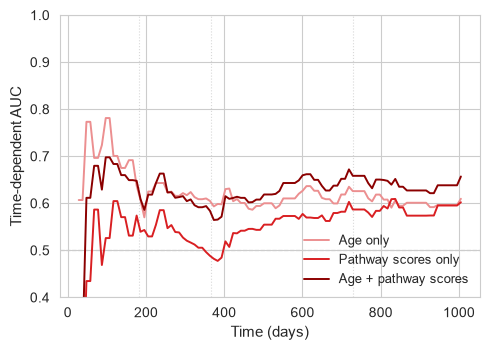

In [65]:
COLOUR, LIGHT, DARK = "#D91F22", "#EC8F90", "#8B0000"

event_times = prog_df.loc[prog_df["event"] == 1, "time"]
time_grid = np.linspace(event_times.min() + 1, event_times.quantile(0.90), 100)

fig, ax = plt.subplots(figsize=(5, 3.6))

for t in time_points:
    ax.axvline(t, color="#d9d9d9", lw=0.8, ls=":", zorder=0)

labels = {"Age only": "Age only", "Pathways only": "Pathway scores only",
          "Age + Pathways": "Age + pathway scores"}

for (label, features), colour in zip(model_sets.items(), [LIGHT, COLOUR, DARK]):
    risk_scores = tcga_models[label].predict_partial_hazard(prog_df[features]).values
    auc, mean_auc = cumulative_dynamic_auc(y_cgga_surv, y_cgga_surv, risk_scores, time_grid)
    ax.plot(time_grid, auc, label=labels.get(label, label), color=colour, lw=1.4)
    print(f"{label}: Mean AUC = {mean_auc:.4f}")

ax.axhline(0.5, color="grey", ls="--", lw=0.8, zorder=0)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Time-dependent AUC", fontsize=11)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

### Calibration

6 months:
  Tertile 1: predicted = 0.663, observed = 0.818
  Tertile 2: predicted = 0.804, observed = 0.955
  Tertile 3: predicted = 0.882, observed = 0.909
1 year:
  Tertile 1: predicted = 0.459, observed = 0.541
  Tertile 2: predicted = 0.657, observed = 0.682
  Tertile 3: predicted = 0.786, observed = 0.676
2 years:
  Tertile 1: predicted = 0.110, observed = 0.165
  Tertile 2: predicted = 0.291, observed = 0.355
  Tertile 3: predicted = 0.497, observed = 0.461


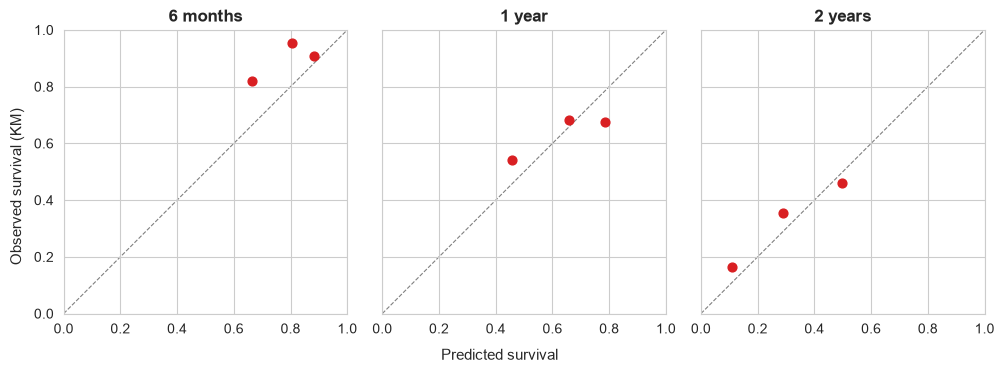

In [66]:
COLOUR = "#D91F22"
n_groups = 3
panel_titles = {182: "6 months", 365: "1 year", 730: "2 years", 1095: "3 years", 1825: "5 years"}

df_model = prog_df[final_features + ["time", "event"]].copy()

fig, axes = plt.subplots(1, len(time_points), figsize=(3.4 * len(time_points), 3.6), sharey=True)
axes = np.atleast_1d(axes)

for ax, t_eval in zip(axes, time_points):
    pred_surv = tcga_cph.predict_survival_function(df_model[final_features], times=[t_eval]).T.squeeze()
    df_cal = df_model.copy()
    df_cal["pred_surv"] = pred_surv.values
    df_cal["group"] = pd.qcut(df_cal["pred_surv"], q=n_groups, labels=False)

    observed, predicted = [], []
    for g in range(n_groups):
        grp = df_cal[df_cal["group"] == g]
        kmf = KaplanMeierFitter().fit(grp["time"], event_observed=grp["event"])
        observed.append(kmf.survival_function_at_times([t_eval]).values[0])
        predicted.append(grp["pred_surv"].mean())

    print(f"{panel_titles[t_eval]}:")
    for g, (p, o) in enumerate(zip(predicted, observed), start=1):
        print(f"  Tertile {g}: predicted = {p:.3f}, observed = {o:.3f}")

    ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=0.8, zorder=0)
    ax.scatter(predicted, observed, color=COLOUR, s=40, zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(panel_titles[t_eval], fontsize=12, fontweight="bold")
    ax.tick_params(labelsize=10)

fig.supxlabel("Predicted survival", fontsize=11)
fig.supylabel("Observed survival (KM)", fontsize=11)
plt.tight_layout()
plt.show()

### Risk Stratification

TCGA median PI (cut-off): 1.0611
High risk n=38, Low risk n=94
Log-rank p = 0.0003
Low Risk median survival: 585 days (95% CI 438-723)
High Risk median survival: 312 days (95% CI 226-406)


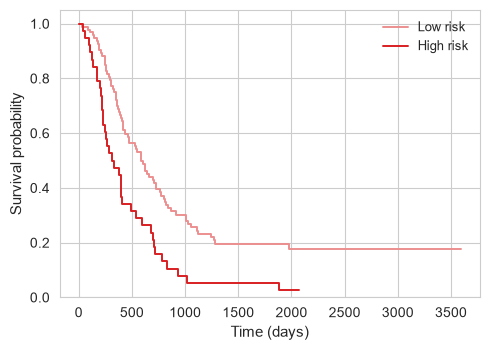

In [67]:
COLOUR, LIGHT = "#D91F22", "#EC8F90"

df_model = prog_df[final_features + ["time", "event"]].copy()
df_model["PI"] = tcga_cph.predict_partial_hazard(df_model[final_features]).values
df_model["risk_group"] = np.where(df_model["PI"] >= tcga_median_pi, "High Risk", "Low Risk")

low = df_model[df_model["risk_group"] == "Low Risk"]
high = df_model[df_model["risk_group"] == "High Risk"]
lr = logrank_test(low["time"], high["time"], event_observed_A=low["event"], event_observed_B=high["event"])

fig, ax = plt.subplots(figsize=(5, 3.6))
kmf_objects = {}
for group, label, colour in [("Low Risk", "Low risk", LIGHT), ("High Risk", "High risk", COLOUR)]:
    mask = df_model["risk_group"] == group
    kmf = KaplanMeierFitter()
    kmf.fit(df_model.loc[mask, "time"], event_observed=df_model.loc[mask, "event"], label=label)
    kmf.plot_survival_function(ax=ax, color=colour, ci_show=False, lw=1.4)
    kmf_objects[group] = kmf

print(f"TCGA median PI (cut-off): {tcga_median_pi:.4f}")
print(f"High risk n={high.shape[0]}, Low risk n={low.shape[0]}")
print(f"Log-rank p = {lr.p_value:.4f}")
fmt = lambda v: "NR" if np.isinf(v) else f"{v:.0f}"
for group, kmf in kmf_objects.items():
    ci = median_survival_times(kmf.confidence_interval_)
    print(f"{group} median survival: {fmt(kmf.median_survival_time_)} days "
          f"(95% CI {fmt(ci.iloc[0, 0])}-{fmt(ci.iloc[0, 1])})")

ax.set_xlabel("Time (days)", fontsize=11)
ax.set_ylabel("Survival probability", fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Group Characterisation

In [68]:
continuous_vars = final_features
var_labels = {f: all_features.get(f, f) for f in continuous_vars}

df_char = prog_df.copy()
df_char.loc[df_model.index, "PI"] = df_model["PI"]
df_char.loc[df_model.index, "risk_group"] = df_model["risk_group"]
df_char = df_char.dropna(subset=["risk_group"])

for var in continuous_vars:
    low_vals = df_char.loc[df_char["risk_group"] == "Low Risk", var].dropna()
    high_vals = df_char.loc[df_char["risk_group"] == "High Risk", var].dropna()
    stat, p = mannwhitneyu(low_vals, high_vals, alternative="two-sided")
    print(f"{var_labels[var]}:")
    print(f"  Low Risk:  median = {low_vals.median():.3f}, IQR = {low_vals.quantile(0.25):.3f}-{low_vals.quantile(0.75):.3f}")
    print(f"  High Risk: median = {high_vals.median():.3f}, IQR = {high_vals.quantile(0.25):.3f}-{high_vals.quantile(0.75):.3f}")
    print(f"  Mann-Whitney U p = {p:.4e}\n")

Age:
  Low Risk:  median = 50.000, IQR = 41.000-58.000
  High Risk: median = 65.000, IQR = 60.000-69.500
  Mann-Whitney U p = 7.5230e-12

FARG Pathway:
  Low Risk:  median = -0.223, IQR = -1.481-0.314
  High Risk: median = 1.158, IQR = 0.656-1.564
  Mann-Whitney U p = 1.7102e-10

Hypoxia Pathway:
  Low Risk:  median = 0.310, IQR = -0.526-0.748
  High Risk: median = 0.122, IQR = -0.065-0.305
  Mann-Whitney U p = 6.0294e-01

Proneural Pathway:
  Low Risk:  median = 0.031, IQR = -1.100-0.630
  High Risk: median = 0.268, IQR = 0.001-0.705
  Mann-Whitney U p = 2.4830e-02



In [69]:
for mut in gbm_trio_mutations:
    if mut not in df_char.columns:
        continue
    ct = pd.crosstab(df_char["risk_group"], df_char[mut])
    if ct.shape == (2, 2):
        _, p = fisher_exact(ct)
        test = "Fisher"
    else:
        _, p, _, _ = chi2_contingency(ct)
        test = "Chi-square"
    print(f"{mut} ({test} p = {p:.4f}):")
    print(ct)
    print()

EGFR_mut (Fisher p = 0.3143):
EGFR_mut    0.0  1.0
risk_group          
High Risk    10    1
Low Risk     24    0

PTEN_mut (Fisher p = 1.0000):
PTEN_mut    0.0  1.0
risk_group          
High Risk     9    2
Low Risk     19    5

TP53_mut (Fisher p = 0.4606):
TP53_mut    0.0  1.0
risk_group          
High Risk     8    3
Low Risk     13   11



FARG Pathway by EGFR: MWU p = 0.400
FARG Pathway by PTEN: MWU p = 0.952
FARG Pathway by TP53: MWU p = 0.045

Hypoxia Pathway by EGFR: MWU p = 0.571
Hypoxia Pathway by PTEN: MWU p = 0.825
Hypoxia Pathway by TP53: MWU p = 0.449

Proneural Pathway by EGFR: MWU p = 0.686
Proneural Pathway by PTEN: MWU p = 0.732
Proneural Pathway by TP53: MWU p = 0.987



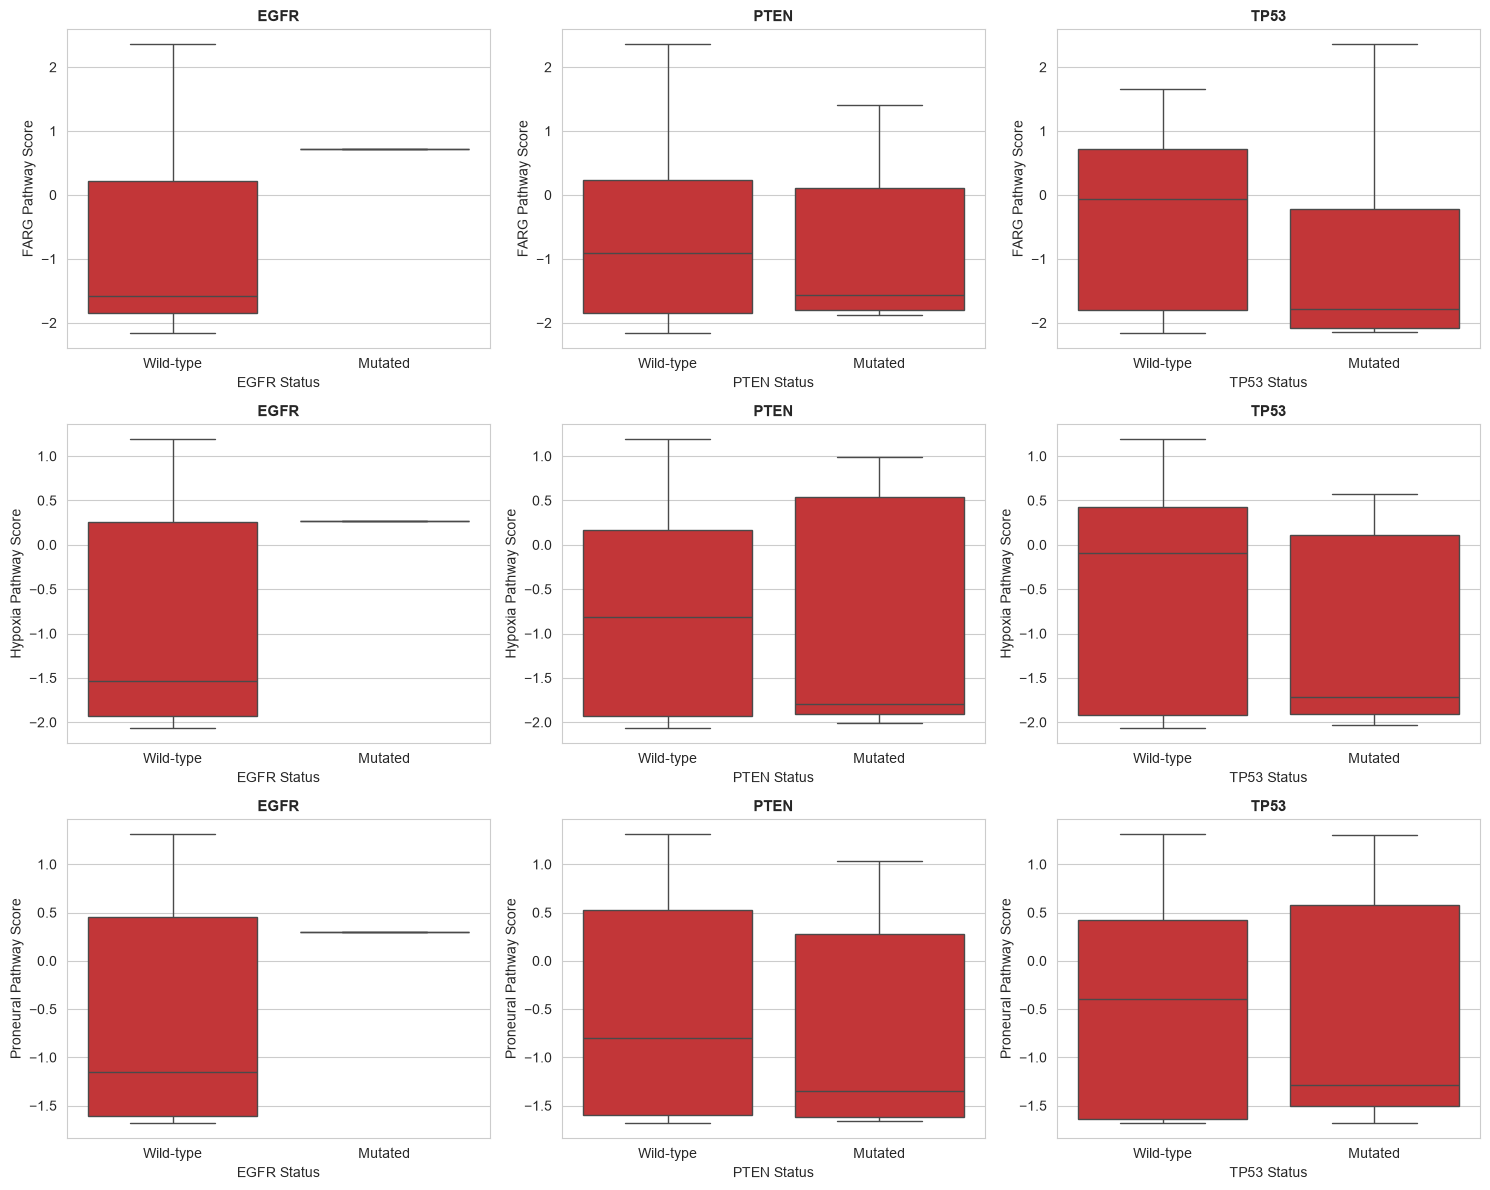

In [70]:
if len(sig_pathways) == 0:
    print("No significant pathways")
else:

    mutations = gbm_trio_mutations
    mut_labels = [m.replace("_mut", "") for m in mutations]

    n_pathways = len(sig_pathways)
    n_muts = len(mutations)

    fig, axes = plt.subplots(n_pathways, n_muts, figsize=(5 * n_muts, 4 * n_pathways))
    if n_pathways == 1:
        axes = [axes]

    for row, pathway_col in enumerate(sig_pathways):
        pathway_label = all_features.get(pathway_col, pathway_col)
        for col, (mut_col, mut_label) in enumerate(zip(mutations, mut_labels)):
            ax = axes[row][col]
            wt_vals  = prog_df.loc[prog_df[mut_col] == 0, pathway_col].dropna()
            mut_vals = prog_df.loc[prog_df[mut_col] == 1, pathway_col].dropna()

            if len(wt_vals) == 0 or len(mut_vals) == 0:
                print(f"{pathway_label} by {mut_label}: not enough patients in one group")
                ax.set_visible(False)
                continue

            _, p = mannwhitneyu(wt_vals, mut_vals, alternative="two-sided")
            p_str = "p < 0.005" if p < 0.005 else f"p = {p:.3f}"
            print(f"{pathway_label} by {mut_label}: MWU {p_str}")

            plot_df = pd.DataFrame({
                "Status": ["Wild-type"] * len(wt_vals) + ["Mutated"] * len(mut_vals),
                "Score":  pd.concat([wt_vals, mut_vals], ignore_index=True),
            })

            sns.boxplot(
                data=plot_df, x="Status", y="Score",
                hue="Status",
                order=["Wild-type", "Mutated"],
                palette={"Wild-type": "#D91F22", "Mutated": "#D91F22"},
                legend=False, ax=ax
            )
            ax.set_title(mut_label, fontsize=11, fontweight="bold")
            ax.set_xlabel(f"{mut_label} Status")
            ax.set_ylabel(f"{pathway_label} Score")

        print()

    plt.tight_layout()
    plt.show()

# Models (Original Features)

In [71]:
def cox_ph_loss(risk, time, event, eps=1e-7):
    order = torch.argsort(time, descending=True)
    risk = risk[order]
    event = event[order]
    log_risk_set = torch.logcumsumexp(risk, dim=0)
    return -((risk - log_risk_set) * event).sum() / (event.sum() + eps)

In [72]:
class DeepSurvNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=16, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

In [73]:
class DeepSurv(BaseEstimator):
    def __init__(self, hidden_dim=16, dropout=0.4, weight_decay=1e-3, lr=1e-3, n_epochs=100, random_state=42):
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.weight_decay = weight_decay
        self.lr = lr
        self.n_epochs = n_epochs
        self.random_state = random_state

    def fit(self, X, y_surv):
        torch.manual_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32)
        time = y_surv["time"].astype(np.float32)
        event = y_surv["event"].astype(np.float32)

        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)

        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        time_t = torch.tensor(time, dtype=torch.float32)
        event_t = torch.tensor(event, dtype=torch.float32)

        self.model_ = DeepSurvNet(X_t.shape[1], self.hidden_dim, self.dropout)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)

        self.model_.train()
        self.loss_history_ = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()
            risk = self.model_(X_t)
            loss = cox_ph_loss(risk, time_t, event_t)
            loss.backward()
            optimizer.step()
            self.loss_history_.append(loss.item())
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        X_scaled = self.scaler_.transform(X)
        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        self.model_.eval()
        with torch.no_grad():
            risk = self.model_(X_t).numpy()
        return risk

    def score(self, X, y_surv):
        risk = self.predict(X)
        c_index = concordance_index_censored(
            y_surv["event"].astype(bool), y_surv["time"], risk
        )[0]
        return c_index

In [74]:
model_dir = Path(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm")

results_final_logreg        = joblib.load(model_dir / "logreg.joblib")
results_final_cph           = joblib.load(model_dir / "cph.joblib")
results_final_rsf           = joblib.load(model_dir / "rsf.joblib")
results_final_gbm           = joblib.load(model_dir / "gbm.joblib")
results_final_ann           = joblib.load(model_dir / "ann.joblib")
dimred_results_final_logreg = joblib.load(model_dir / "dimred_logreg.joblib")
dimred_results_final_cph    = joblib.load(model_dir / "dimred_cph.joblib")
dimred_results_final_rsf    = joblib.load(model_dir / "dimred_rsf.joblib")
dimred_results_final_gbm    = joblib.load(model_dir / "dimred_gbm.joblib")
dimred_results_final_ann    = joblib.load(model_dir / "dimred_ann.joblib")

results_cv_logreg       = joblib.load(model_dir / "cv_logreg.joblib")
results_cv_cph          = joblib.load(model_dir / "cv_cph.joblib")
results_cv_rsf          = joblib.load(model_dir / "cv_rsf.joblib")
results_cv_gbm          = joblib.load(model_dir / "cv_gbm.joblib")
results_cv_ann          = joblib.load(model_dir / "cv_ann.joblib")
dimred_results_cv_logreg = joblib.load(model_dir / "dimred_cv_logreg.joblib")
dimred_results_cv_cph    = joblib.load(model_dir / "dimred_cv_cph.joblib")
dimred_results_cv_rsf    = joblib.load(model_dir / "dimred_cv_rsf.joblib")
dimred_results_cv_gbm    = joblib.load(model_dir / "dimred_cv_gbm.joblib")
dimred_results_cv_ann    = joblib.load(model_dir / "dimred_cv_ann.joblib")

## Statistical Models

### Logistic Regression

In [75]:
assert merged_df.index.equals(merged_mutation_df.index)
assert merged_df.index.equals(merged_expression_df.index)

In [76]:
tcga_expr = pd.read_csv(model_dir / "merged_df.csv")
shared_genes = [g for g in merged_expression_df.columns if g in tcga_expr.columns]
cgga_expr = merged_expression_df[shared_genes]
cgga_z = (cgga_expr - cgga_expr.mean()) / cgga_expr.std(ddof=0)
cgga_z = cgga_z.fillna(0)
harmonised_expression_df = cgga_z * tcga_expr[shared_genes].std(ddof=0) + tcga_expr[shared_genes].mean()
print(f"Harmonised {len(shared_genes)}/{merged_expression_df.shape[1]} genes to the TCGA scale")

y = merged_df["event"]

clinical_log = merged_df[["gender", "age"]].copy()
mutation_log = merged_mutation_df.copy()
expression_log = harmonised_expression_df.copy()

Harmonised 68/68 genes to the TCGA scale


In [77]:
model_1_log = clinical_log
model_2_log = pd.concat([clinical_log, mutation_log], axis=1)
model_3_log = pd.concat([clinical_log, expression_log], axis=1)
model_4_log = pd.concat([clinical_log, mutation_log, expression_log], axis=1)

In [78]:
def validate_logreg(name, X_cgga, y_cgga, tcga_results):
    model, _, _, _, scaler, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    X_val_scaled = scaler.transform(X_val)
    preds = model.predict_proba(X_val_scaled)[:, 1]
    return roc_auc_score(y_cgga, preds)

cgga_models = {"Model 1": model_1_log, "Model 2": model_2_log,
               "Model 3": model_3_log, "Model 4": model_4_log}

results_val_logreg = {}
for name, X in cgga_models.items():
    auc = validate_logreg(name, X, y, results_final_logreg)
    results_val_logreg[name] = auc
    print(f"{name}: Validation AUC = {auc:.3f}")

Model 1: Validation AUC = 0.607
Model 2: Validation AUC = 0.571
Model 3: Validation AUC = 0.469
Model 4: Validation AUC = 0.423


### Cox Proportional Hazards

In [79]:
y_surv = np.array(
    [(bool(e), float(t)) for e, t in zip(merged_df["event"], merged_df["time"])],
    dtype=[("event", bool), ("time", float)]
)

In [80]:
clinical_cph = merged_df[["gender", "age"]].copy()
mutation_cph = merged_mutation_df.copy()
expression_cph = harmonised_expression_df.copy()

In [81]:
model_1_cph = clinical_cph
model_2_cph = pd.concat([clinical_cph, mutation_cph], axis=1)
model_3_cph = pd.concat([clinical_cph, expression_cph], axis=1)
model_4_cph = pd.concat([clinical_cph, mutation_cph, expression_cph], axis=1)

In [82]:
def validate_cph(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, scaler, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    X_val_scaled = scaler.transform(X_val)
    c_index = model.score(X_val_scaled, y_surv_cgga)
    return c_index

cgga_models_cph = {"Model 1": model_1_cph, "Model 2": model_2_cph,
                   "Model 3": model_3_cph, "Model 4": model_4_cph}

results_val_cph = {}
for name, X in cgga_models_cph.items():
    c = validate_cph(name, X, y_surv, results_final_cph)
    results_val_cph[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.672
Model 2: Validation C-index = 0.617
Model 3: Validation C-index = 0.657
Model 4: Validation C-index = 0.531


## Machine Learning Models

### Random Survival Forest

In [83]:
model_1_rsf = model_1_cph
model_2_rsf = model_2_cph
model_3_rsf = model_3_cph
model_4_rsf = model_4_cph

In [84]:
def validate_rsf(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_rsf = {"Model 1": model_1_rsf, "Model 2": model_2_rsf,
                   "Model 3": model_3_rsf, "Model 4": model_4_rsf}

results_val_rsf = {}
for name, X in cgga_models_rsf.items():
    c = validate_rsf(name, X, y_surv, results_final_rsf)
    results_val_rsf[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.704
Model 2: Validation C-index = 0.604
Model 3: Validation C-index = 0.568
Model 4: Validation C-index = 0.572


### Gradient Boosting

In [85]:
model_1_gbm = model_1_cph
model_2_gbm = model_2_cph
model_3_gbm = model_3_cph
model_4_gbm = model_4_cph

In [86]:
def validate_gbm(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_gbm = {"Model 1": model_1_gbm, "Model 2": model_2_gbm,
                   "Model 3": model_3_gbm, "Model 4": model_4_gbm}

results_val_gbm = {}
for name, X in cgga_models_gbm.items():
    c = validate_gbm(name, X, y_surv, results_final_gbm)
    results_val_gbm[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.696
Model 2: Validation C-index = 0.642
Model 3: Validation C-index = 0.584
Model 4: Validation C-index = 0.615


### Artificial Neural Network

In [87]:
model_1_ann = model_1_cph
model_2_ann = model_2_cph
model_3_ann = model_3_cph
model_4_ann = model_4_cph

In [88]:
def validate_ann(name, X_cgga, y_surv_cgga, tcga_results):
    model, _, _, _, kept_cols = tcga_results[name]
    missing = [c for c in kept_cols if c not in X_cgga.columns]
    if missing:
        print(f"  WARNING: {len(missing)} features missing from CGGA: {missing}")
    X_val = X_cgga.reindex(columns=kept_cols, fill_value=0)
    return model.score(X_val, y_surv_cgga)

cgga_models_ann = {"Model 1": model_1_ann, "Model 2": model_2_ann,
                   "Model 3": model_3_ann, "Model 4": model_4_ann}

results_val_ann = {}
for name, X in cgga_models_ann.items():
    c = validate_ann(name, X, y_surv, results_final_ann)
    results_val_ann[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.691
Model 2: Validation C-index = 0.585
Model 3: Validation C-index = 0.556
Model 4: Validation C-index = 0.540


# Models (Reduced Features)

In [89]:
dimred_clinical_log   = dimred_merged_df[["gender", "age"]].copy()
dimred_mutation_log   = dimred_merged_df[gbm_trio_mutations].copy()
dimred_expression_log = dimred_merged_df[score_cols].copy()

dimred_model_1_log = dimred_clinical_log
dimred_model_2_log = pd.concat([dimred_clinical_log, dimred_mutation_log], axis=1)
dimred_model_3_log = pd.concat([dimred_clinical_log, dimred_expression_log], axis=1)
dimred_model_4_log = pd.concat([dimred_clinical_log, dimred_mutation_log, dimred_expression_log], axis=1)

In [90]:
cgga_dimred_models = {"Model 1": dimred_model_1_log, "Model 2": dimred_model_2_log,
                      "Model 3": dimred_model_3_log, "Model 4": dimred_model_4_log}

In [91]:
dimred_results_val_logreg = {}
for name, X in cgga_dimred_models.items():
    auc = validate_logreg(name, X, y, dimred_results_final_logreg)
    dimred_results_val_logreg[name] = auc
    print(f"{name}: Validation AUC = {auc:.3f}")

Model 1: Validation AUC = 0.607
Model 2: Validation AUC = 0.526
Model 3: Validation AUC = 0.638
Model 4: Validation AUC = 0.556


In [92]:
dimred_results_val_cph = {}
for name, X in cgga_dimred_models.items():
    c = validate_cph(name, X, y_surv, dimred_results_final_cph)
    dimred_results_val_cph[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.672
Model 2: Validation C-index = 0.663
Model 3: Validation C-index = 0.660
Model 4: Validation C-index = 0.630


In [93]:
dimred_results_val_rsf = {}
for name, X in cgga_dimred_models.items():
    c = validate_rsf(name, X, y_surv, dimred_results_final_rsf)
    dimred_results_val_rsf[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.704
Model 2: Validation C-index = 0.597
Model 3: Validation C-index = 0.614
Model 4: Validation C-index = 0.586


In [94]:
dimred_results_val_gbm = {}
for name, X in cgga_dimred_models.items():
    c = validate_gbm(name, X, y_surv, dimred_results_final_gbm)
    dimred_results_val_gbm[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.696
Model 2: Validation C-index = 0.621
Model 3: Validation C-index = 0.658
Model 4: Validation C-index = 0.630


In [95]:
dimred_results_val_ann = {}
for name, X in cgga_dimred_models.items():
    c = validate_ann(name, X, y_surv, dimred_results_final_ann)
    dimred_results_val_ann[name] = c
    print(f"{name}: Validation C-index = {c:.3f}")

Model 1: Validation C-index = 0.691
Model 2: Validation C-index = 0.642
Model 3: Validation C-index = 0.504
Model 4: Validation C-index = 0.607


# Model and Method Evaluation

In [96]:
model_names = ["Model 1", "Model 2", "Model 3", "Model 4"]

val_rows = []
for name in model_names:
    val_rows.append({
        "Model": name, "Feature Set": "Original",
        "LogReg TCGA Test AUC":     results_cv_logreg[name][0],
        "LogReg TCGA Test AUC SD":  results_cv_logreg[name][2],
        "LogReg TCGA Train AUC":    results_cv_logreg[name][1],
        "LogReg CGGA Val AUC":      results_val_logreg[name],
        "CPH TCGA Test C-index":    results_cv_cph[name][0],
        "CPH TCGA Test C-index SD": results_cv_cph[name][2],
        "CPH TCGA Train C-index":   results_cv_cph[name][1],
        "CPH CGGA Val C-index":     results_val_cph[name],
        "RSF TCGA Test C-index":    results_cv_rsf[name][0],
        "RSF TCGA Test C-index SD": results_cv_rsf[name][2],
        "RSF TCGA Train C-index":   results_cv_rsf[name][1],
        "RSF CGGA Val C-index":     results_val_rsf[name],
        "GBM TCGA Test C-index":    results_cv_gbm[name][0],
        "GBM TCGA Test C-index SD": results_cv_gbm[name][2],
        "GBM TCGA Train C-index":   results_cv_gbm[name][1],
        "GBM CGGA Val C-index":     results_val_gbm[name],
        "ANN TCGA Test C-index":    results_cv_ann[name][0],
        "ANN TCGA Test C-index SD": results_cv_ann[name][2],
        "ANN TCGA Train C-index":   results_cv_ann[name][1],
        "ANN CGGA Val C-index":     results_val_ann[name],
    })
    val_rows.append({
        "Model": name, "Feature Set": "Reduced",
        "LogReg TCGA Test AUC":     dimred_results_cv_logreg[name][0],
        "LogReg TCGA Test AUC SD":  dimred_results_cv_logreg[name][2],
        "LogReg TCGA Train AUC":    dimred_results_cv_logreg[name][1],
        "LogReg CGGA Val AUC":      dimred_results_val_logreg[name],
        "CPH TCGA Test C-index":    dimred_results_cv_cph[name][0],
        "CPH TCGA Test C-index SD": dimred_results_cv_cph[name][2],
        "CPH TCGA Train C-index":   dimred_results_cv_cph[name][1],
        "CPH CGGA Val C-index":     dimred_results_val_cph[name],
        "RSF TCGA Test C-index":    dimred_results_cv_rsf[name][0],
        "RSF TCGA Test C-index SD": dimred_results_cv_rsf[name][2],
        "RSF TCGA Train C-index":   dimred_results_cv_rsf[name][1],
        "RSF CGGA Val C-index":     dimred_results_val_rsf[name],
        "GBM TCGA Test C-index":    dimred_results_cv_gbm[name][0],
        "GBM TCGA Test C-index SD": dimred_results_cv_gbm[name][2],
        "GBM TCGA Train C-index":   dimred_results_cv_gbm[name][1],
        "GBM CGGA Val C-index":     dimred_results_val_gbm[name],
        "ANN TCGA Test C-index":    dimred_results_cv_ann[name][0],
        "ANN TCGA Test C-index SD": dimred_results_cv_ann[name][2],
        "ANN TCGA Train C-index":   dimred_results_cv_ann[name][1],
        "ANN CGGA Val C-index":     dimred_results_val_ann[name],
    })

val_df = pd.DataFrame(val_rows).round(3)
val_df

,Model,Feature Set,LogReg TCGA Test AUC,LogReg TCGA Test AUC SD,LogReg TCGA Train AUC,LogReg CGGA Val AUC,CPH TCGA Test C-index,CPH TCGA Test C-index SD,CPH TCGA Train C-index,CPH CGGA Val C-index,...,RSF TCGA Train C-index,RSF CGGA Val C-index,GBM TCGA Test C-index,GBM TCGA Test C-index SD,GBM TCGA Train C-index,GBM CGGA Val C-index,ANN TCGA Test C-index,ANN TCGA Test C-index SD,ANN TCGA Train C-index,ANN CGGA Val C-index
0,Model 1,Original,0.578,0.050,0.589,0.607,0.633,0.049,0.628,0.672,...,0.657,0.704,0.607,0.066,0.660,0.696,0.640,0.056,0.633,0.691
1,Model 1,Reduced,0.578,0.050,0.589,0.607,0.633,0.049,0.628,0.672,...,0.657,0.704,0.607,0.066,0.660,0.696,0.640,0.056,0.633,0.691
2,Model 2,Original,0.583,0.073,0.616,0.571,0.644,0.058,0.637,0.617,...,0.677,0.604,0.617,0.058,0.685,0.642,0.586,0.054,0.617,0.585
3,Model 2,Reduced,0.588,0.070,0.620,0.526,0.634,0.049,0.629,0.663,...,0.681,0.597,0.626,0.054,0.683,0.621,0.620,0.043,0.635,0.642
4,Model 3,Original,0.655,0.058,0.745,0.469,0.648,0.024,0.676,0.657,...,0.851,0.568,0.604,0.048,0.880,0.584,0.602,0.045,0.768,0.556
5,Model 3,Reduced,0.499,0.051,0.606,0.638,0.628,0.034,0.645,0.660,...,0.748,0.614,0.604,0.050,0.736,0.658,0.589,0.053,0.621,0.504
6,Model 4,Original,0.644,0.051,0.753,0.423,0.651,0.030,0.700,0.531,...,0.825,0.572,0.585,0.054,0.939,0.615,0.637,0.031,0.812,0.540
7,Model 4,Reduced,0.547,0.055,0.644,0.556,0.637,0.041,0.644,0.630,...,0.758,0.586,0.608,0.047,0.763,0.630,0.600,0.033,0.677,0.607


# Model Export

In [97]:
val_df_gbm = val_df.copy()
val_df_gbm.to_csv(r"C:\Users\abbyn\OneDrive\Desktop\Research Project\TCGA\saved_models\tcga_gbm\val_df_gbm.csv", index=False)